# **Section 5: Logistic Regression**

In this notebook, I will train and evaluate logistic regressions. I will start with a baseline model using default parameters, and will then tune the regularization parameter (C) using a cross-validated grid search. Finally, I will look at which features contribute the most to predicting resistance, and save the results.

#### **Contents**
1. **Import data**
2. **Basic logistic regression**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Biomarker identification**
   - 5.1 Load cluster names
   - 5.2 Extract feature importance
   - 5.3 Export biomarkers
6. **Saving model results**


## **1. Importing the Data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')
sns.set_palette("pastel")

In [2]:
# Load features and labels
snp_train = pd.read_csv("Data/snp_train_selected.csv", index_col=0)
snp_test = pd.read_csv("Data/snp_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = snp_train.values
y_train = profiles_train.values

X_test = snp_test.values
y_test = profiles_test.values

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (176, 796)
Test set shape: (50, 796)
Categories: [0 1]


## **2. Basic Logistic Regression**

### **2.1 Training and fitting the model**

Let's start with a basic logistic regression model using default parameters (C=1). I chose to use an elastic net regression (which combines L1 and L2 regularization) with a l1_ratio of 0.5. 

In [3]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=1.0, max_iter=1000, random_state=4)
)

# Train the model
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,796
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### **2.2 Evaluating the model**

In [4]:
# Evaluate on training and test sets
accuracy_train = logreg.score(X_train, y_train)
accuracy_test = logreg.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.9886
Accuracy test set: 0.3600


### **2.3 Classification report and confusion matrix**

In [5]:
# Get predictions
y_test_pred = logreg.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.17      0.24        30
           1       0.34      0.65      0.45        20

    accuracy                           0.36        50
   macro avg       0.38      0.41      0.34        50
weighted avg       0.39      0.36      0.32        50



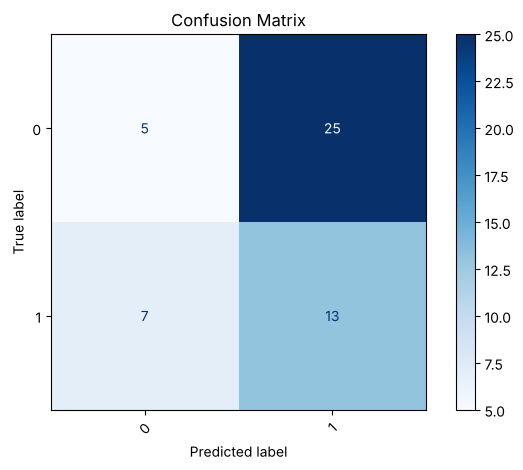

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=logreg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

We see that this basic regression model does not perform well at all on the test set, even though it performs quite well on the training set. This is likely due to the fact that the strains in the test set are quite different from the strains in the training set (as they belong to a different lineage). Perhaps the SNPs that drive resistance in the training set aren't the same as those that are related to resistance in the test set... In any case, let's see if we can improve this using hyperparameter tuning.

## **3. Hyperparameter Tuning**

Let's use a cross-validated grid search to find the optimal regularization parameter C and L1 ratio.

### **3.1 Grid Search**

In [7]:
# Create Logistic Regression pipeline
logreg_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=1, penalty="elasticnet", solver="saga")
)

# Define parameter grid
param_grid = {
    "logisticregression__C": np.logspace(-2, 2, 5),
    "logisticregression__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]
}

# Create grid search
grid_search = GridSearchCV(
    logreg_pipeline,
    param_grid,
    cv=4,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
print("Performing grid search")
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

Performing grid search



Best parameters: {'logisticregression__C': np.float64(1.0), 'logisticregression__l1_ratio': 0.75}
Best cross-validation score: 0.7670


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score', 
    'mean_train_score', 'std_train_score',
    'param_logisticregression__C'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.727273        0.027835          0.920455         0.013657   
1         0.579545        0.011364          0.625000         0.067865   
2         0.585227        0.009841          0.585227         0.003280   
3         0.585227        0.009841          0.585227         0.003280   
4         0.585227        0.009841          0.585227         0.003280   

   param_logisticregression__C  
0                         0.01  
1                         0.01  
2                         0.01  
3                         0.01  
4                         0.01  


### **3.3 Visualizing Training/Validation curves**

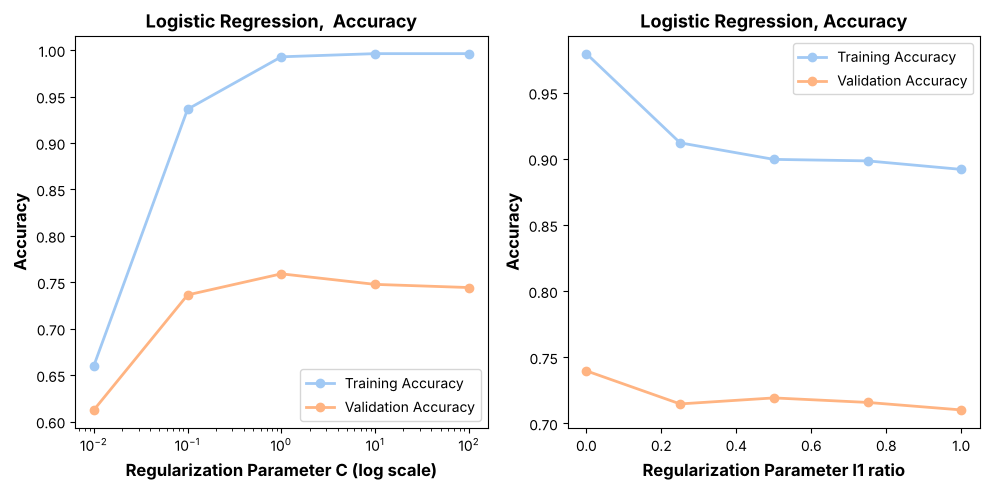

In [9]:
# Sort results by C value for plotting
fig, axes = plt.subplots(1, 2, figsize=(10,5))

axes[0].semilogx(
    cv_results.groupby("param_logisticregression__C")['mean_train_score'].mean().index,
    cv_results.groupby("param_logisticregression__C")['mean_train_score'].mean().values,
    label='Training Accuracy',
    marker='o',
    linewidth=2
)
axes[0].semilogx(
    cv_results.groupby("param_logisticregression__C")['mean_test_score'].mean().index,
    cv_results.groupby("param_logisticregression__C")['mean_test_score'].mean().values,
    label='Validation Accuracy',
    marker='o',
    linewidth=2,
)

axes[0].set_xlabel('Regularization Parameter C (log scale)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title('Logistic Regression,  Accuracy', fontsize=13, fontweight='bold')
axes[0].legend()

axes[1].plot(
    cv_results.groupby("param_logisticregression__l1_ratio")['mean_train_score'].mean().index,
    cv_results.groupby("param_logisticregression__l1_ratio")['mean_train_score'].mean().values,
    label='Training Accuracy',
    marker='o',
    linewidth=2
)
axes[1].plot(
    cv_results.groupby("param_logisticregression__l1_ratio")['mean_test_score'].mean().index,
    cv_results.groupby("param_logisticregression__l1_ratio")['mean_test_score'].mean().values,
    label='Validation Accuracy',
    marker='o',
    linewidth=2
)

axes[1].set_xlabel('Regularization Parameter l1 ratio', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[1].set_title('Logistic Regression, Accuracy', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig("Figures/04_logreg_training_curves", dpi=300, bbox_inches='tight')
plt.show()

## **4. Evaluate Best Model**

### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_logreg = grid_search.best_estimator_
accuracy_test_best = best_logreg.score(X_test, y_test)

print(f"\nBest model test accuracy: {accuracy_test_best:.4f}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")


Best model test accuracy: 0.3600
Best parameters: {'logisticregression__C': np.float64(1.0), 'logisticregression__l1_ratio': 0.75}
Best CV score: 0.7670


### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_logreg.predict(X_test)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_best))


Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.17      0.24        30
           1       0.34      0.65      0.45        20

    accuracy                           0.36        50
   macro avg       0.38      0.41      0.34        50
weighted avg       0.39      0.36      0.32        50



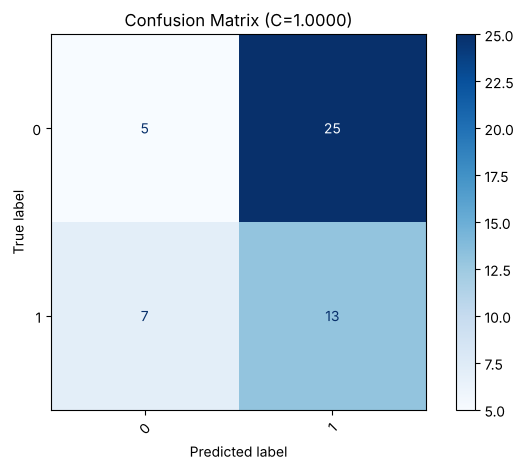

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_logreg.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_logreg.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix (C={grid_search.best_params_['logisticregression__C']:.4f})")
plt.tight_layout()
plt.savefig("Figures/04_logreg_cm", dpi=300, bbox_inches='tight')
plt.show()

The cross-validation and grid search do not seem to have improved the performance of the model. It still performs very poorly on the test set. 

### **4.3 ROC curve and AUC score**

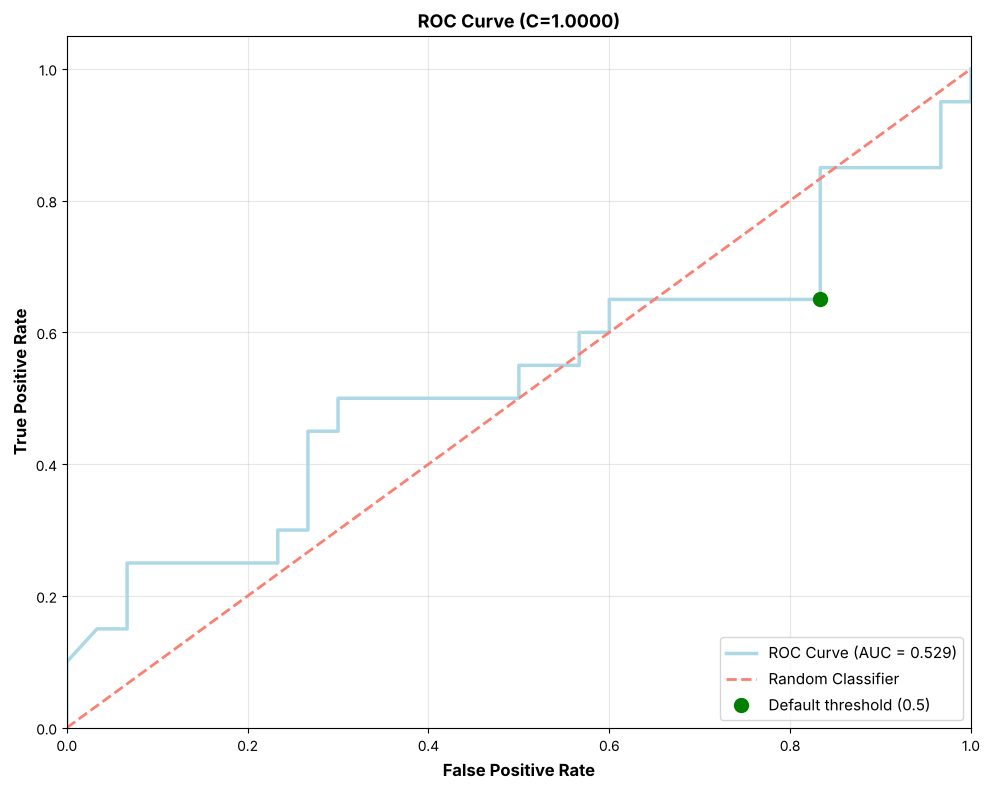


AUC Score: 0.5292
At default threshold (0.5):
True Positive Rate: 0.650 (detects 65.0% of resistants)
False Positive Rate: 0.833 (83.3% of susceptibles are misclassified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_logreg.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='lightblue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='salmon', lw=2, linestyle='--', label='Random Classifier')

# Mark 0.5 threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (C={grid_search.best_params_["logisticregression__C"]:.4f})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/04_logreg_ROC", dpi=300, bbox_inches='tight')
plt.show()


print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At default threshold (0.5):")
print(f"True Positive Rate: {tpr[default_idx]:.3f} (detects {tpr[default_idx]*100:.1f}% of resistants)")
print(f"False Positive Rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptibles are misclassified)")

## **5. Biomarker Identification**
Let's now have a look at which features contribute the most to the model.
We will identify biomarkers (features that contribute the most to the model) using **Model Weights**, by looking at the coefficients from the logistic regression model

### **5.1 Load feature names**
We now don't have access directly to the original features, as they were grouped into clusters in the third notebook. We do however, have the names of the clusters, and a list of features associated with each cluster in the file Data/clusters.csv. Let's extract the cluster names and let's also import the cluster.csv file.

In [14]:
cluster_names = snp_train.columns.values

In [15]:
features_to_cluster = pd.read_csv("Data/clusters.csv")

In [16]:
features_to_cluster.head()

,cluster,snp,cluster_size
0,0,snp__NZ_AP028078.1_1825474_C_T,1
1,1,snp__NZ_AP028077.1_1061328_AGTCGCCGAAGTCGCCGAA...,1
2,2,snp__NZ_AP028077.1_1565260_C_T,1
3,3,snp__NZ_AP028078.1_2219598_T_G,1
4,4,snp__NZ_AP028077.1_72372_G_A,1


### **5.2 Computing feature importance**
Let's now see which clusters contribute the most to predicting resistance using the best model. 

In [17]:
# Extract coefficients from the best model
coefficients = best_logreg.named_steps['logisticregression'].coef_[0]

# Create dataframe with cluster names and coefficients
coef_df = pd.DataFrame({
    'feature': cluster_names,
    'coefficient': coefficients,
    'abs_coefficient': np.abs(coefficients)
})

# Sort by absolute coefficient value
coef_df = coef_df.sort_values('abs_coefficient', ascending=False)

print(f"\nTop 20 Clusters:")
print(coef_df.head(20)[['feature', 'coefficient', 'abs_coefficient']].to_string(index=False))

# Separate into resistance-associated (positive) and susceptibility-associated (negative)
resistance_biomarkers = coef_df[coef_df['coefficient'] > 0].head(10)
susceptibility_biomarkers = coef_df[coef_df['coefficient'] < 0].head(10)

print(f"\n\nTop 10 Resistance-Associated Clusters:")
print(resistance_biomarkers[['feature', 'coefficient']].to_string(index=False))

print(f"\n\nTop 10 Susceptibility-Associated Clusters:")
print(susceptibility_biomarkers[['feature', 'coefficient']].to_string(index=False))


Top 20 Clusters:
feature  coefficient  abs_coefficient
    773     0.820065         0.820065
    370    -0.730109         0.730109
     92    -0.723534         0.723534
    454    -0.590173         0.590173
    112    -0.504764         0.504764
    217    -0.502584         0.502584
    154     0.466085         0.466085
    714     0.446262         0.446262
    103    -0.428237         0.428237
    105    -0.396801         0.396801
    658    -0.392493         0.392493
    208     0.376527         0.376527
    159    -0.376353         0.376353
    661    -0.376188         0.376188
    497     0.355343         0.355343
    602    -0.335474         0.335474
    175    -0.327511         0.327511
    161     0.306763         0.306763
    228     0.299689         0.299689
    181     0.298967         0.298967


Top 10 Resistance-Associated Clusters:
feature  coefficient
    773     0.820065
    154     0.466085
    714     0.446262
    208     0.376527
    497     0.355343
    161     0.306

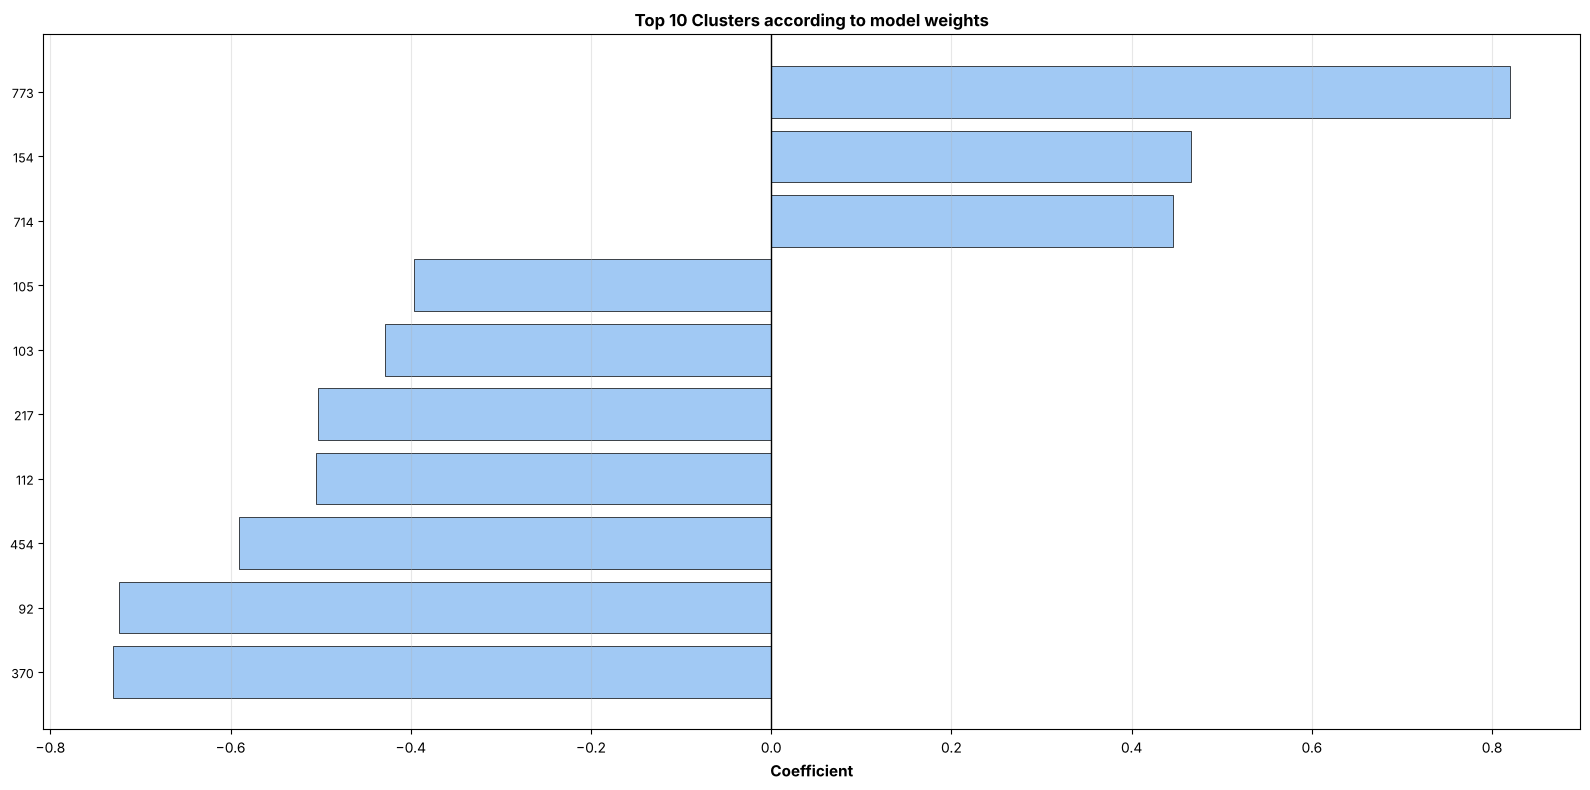

In [18]:
# Visualize top clusters by model weights
fig, axes = plt.subplots(1, 1, figsize=(16, 8))

# Top 10 features by absolute coefficient
ax = axes
top_features = coef_df.head(10).sort_values("abs_coefficient")
top_features = top_features.sort_values("coefficient")
ax.barh(range(len(top_features)), top_features['coefficient'], edgecolor='black', linewidth=0.5)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels([f.replace('cnv_depth__', '') for f in top_features['feature']], fontsize=9)
ax.set_xlabel('Coefficient', fontweight='bold', fontsize=11)
ax.set_title('Top 10 Clusters according to model weights', fontweight='bold', fontsize=12)
ax.axvline(0, color='black', linestyle='-', linewidth=1)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('Figures/04_logreg_biomarkers_weights.png', dpi=300, bbox_inches='tight')
plt.show()

We can now generate a list with all original features contributing to these clusters.

In [19]:
print(features_to_cluster[features_to_cluster.cluster.isin(top_features.index)])

      cluster                                                snp  cluster_size
356        92  snp__NZ_AP028077.1_535001_AACGCGAGACGCGAG_AACG...             1
380       103                  snp__NZ_AP028077.1_3720787_G_GGCA             1
382       105  snp__NZ_AP028077.1_77085_A_AACGAATTGGACGAATTGG...             1
389       112  snp__NZ_AP028077.1_1402777_C_CCGTGCGCGGCCCGTCG...             1
449       154  snp__NZ_AP028077.1_3306069_AGCCGAGCCGAGC_GCACGGCA             1
516       217                     snp__NZ_AP028078.1_1259604_C_A             1
719       370    snp__NZ_AP028077.1_991025_A_ACCACCGCCGTTGCCACCG             1
819       454                      snp__NZ_AP028077.1_154813_G_A             2
820       454                      snp__NZ_AP028077.1_154864_C_T             2
1115      714                      snp__NZ_AP028077.1_429366_C_T             1
1176      773                      snp__NZ_AP028077.1_690660_T_A             1


I won't go too deeply into the biological interpretation here, but it's interesting to see that a lot of the variants that are related to resistance seem to be big substitutions and not only single nucleotide SNPs. This could make sense, as they likely have a higher impact on the gene than a single nucleotide change. 

### **5.3 Save Biomarker results**

In [20]:
# Save biomarker results
features_to_cluster[features_to_cluster.cluster.isin(top_features.index)].to_csv("Results/biomarkers_logreg_coefs.csv", index=False)

## **6. Save model results**

In [21]:
import csv
import os

# Store results
results = {
    'model': 'Logistic Regression',
    'hyperparameters': f"C={grid_search.best_params_['logisticregression__C']:.4f}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = "Results/model_results.csv"

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: Logistic Regression
Hyperparameters: C=1.0000
Test Accuracy: 0.3600
CV Score: 0.7670
